# `golftracker` 2.0 benchmark

This notebook reviews the published 2.0 wheel, the installed site-packages source, the project's supplied video/JSON/pickle trio, and a real MediaPipe run. `golftracker` is a frame-level data capture concept, but the published wheel is not reproducibly installable as declared.

Observed native install blockers:

1. `mediapipe==0.8.10` has no matching distribution on this Python 3.9/Linux index.
2. Current pip rejects the malformed `tune_line_det = scripts.tune_line_det` entry point (no callable suffix).
3. The wheel omits the `scripts` package targeted by every CLI wrapper.

For library evaluation only, the unmodified wheel contents were installed with MediaPipe 0.10.14 (same legacy `mp.solutions` API), protobuf 4.25.9, OpenCV contrib 4.11, and NumPy 1.26.4. This override is not claimed to satisfy the package metadata.

In [1]:
from pathlib import Path
from collections import Counter
import ast, inspect, json, os, platform, subprocess, sys
import importlib.metadata as md
import cv2, matplotlib.pyplot as plt, numpy as np, pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SAMPLES = ROOT / "data" / "raw" / "golftracker_samples"
OUT = ROOT / "outputs" / "golftracker"
OUT.mkdir(parents=True, exist_ok=True)

import golftracker
from golftracker import (club_head_detector, club_head_params, golf_swing_factory,
                         golf_swing_repository, gt_const, media_pipe_operation,
                         video_utils)

versions = pd.DataFrame({"value": {
    "Python": platform.python_version(), "golftracker": md.version("golftracker"),
    "declared MediaPipe": "0.8.10 (unavailable)", "tested MediaPipe": md.version("mediapipe"),
    "declared protobuf": "3.20.0", "tested protobuf": md.version("protobuf"),
    "OpenCV": cv2.__version__, "NumPy": np.__version__, "pandas": pd.__version__,
    "scikit-learn": md.version("scikit-learn"),
}})
display(versions)
print("import path:", inspect.getfile(golftracker))
print("declared requirements:", md.requires("golftracker"))

,value
Python,3.9.25
golftracker,2.0
declared MediaPipe,0.8.10 (unavailable)
tested MediaPipe,0.10.14
declared protobuf,3.20.0
tested protobuf,4.25.9
OpenCV,4.11.0
NumPy,1.26.4
pandas,2.3.3
scikit-learn,1.6.1


import path: /home/tsispace/Documents/GitHub/golf-balance/envs/golftracker/lib/python3.9/site-packages/golftracker/__init__.py
declared requirements: ['opencv-contrib-python', 'protobuf ==3.20.0', 'mediapipe ==0.8.10', 'numpy', 'scikit-learn', 'pandas', "pytest >=3.7 ; extra == 'dev'", "check-manifest ; extra == 'dev'", "twine ; extra == 'dev'"]


## Installed source structure and processing architecture

The wheel's importable `golftracker/` package is present, but `scripts/` is absent. Data flow in the intended repository workflow is:

`video -> all frames in RAM -> MediaPipe landmarks -> optional sklearn pose classifier -> pickle -> GUI pose/club labels -> straight-line club interpolation -> JSON -> golftrainer`

Key implementation details:

- `media_pipe_operation.run`: creates and destroys a MediaPipe `Pose` object **inside every frame iteration**. Despite `static_image_mode=False`, temporal tracker state is discarded. It enables segmentation but discards the mask.
- `pose_model.PoseModel`: classifies each 132-value landmark row with a supplied sklearn model and accepts maximum class probability above 0.7. No temporal smoothing/state machine is used.
- `club_head_detector.ClubHeadDetector`: copies manual labels and linearly interpolates missing frames between adjacent labels. It is not an OpenCV tracker.
- Canny/Hough modules exist, but are tuning experiments and are not connected to `ClubHeadDetector.run`.
- The JSON/pickle model retains 33 `(x,y,z,visibility)` pose landmarks per frame, pose labels, and one club-head `(x,y,source)` per frame. There is no ball field or shaft endpoints.

In [2]:
package_dir = Path(inspect.getfile(golftracker)).parent
rows=[]
for path in sorted(package_dir.glob("*.py")):
    tree=ast.parse(path.read_text())
    defs=[f"{n.name}:{n.lineno}" for n in tree.body if isinstance(n,(ast.FunctionDef,ast.ClassDef))]
    rows.append((path.name,len(path.read_text().splitlines()),", ".join(defs)))
display(pd.DataFrame(rows,columns=["file","lines","definitions"]))

,file,lines,definitions
0,__init__.py,0,
1,canny_edge_detector.py,34,CannyEdgeDetector:9
2,canny_edge_params.py,29,CannyEdgeParams:5
3,club_head_detector.py,91,"ClubHeadDetector:8, find_consecutive_invalid_i..."
4,club_head_params.py,25,ClubHeadParams:7
5,club_head_result.py,49,ClubHeadResult:7
6,double_pendlum.py,24,draw:5
7,file_utils.py,74,"basename:7, search_file:21, write_to_csv:36, r..."
8,geom.py,243,"split_pt:7, to_pairs:18, scale:28, origin_to_c..."
9,golf_swing.py,130,GolfSwing:12


## Published CLI failure

The wrapper exists because pip partially generated it, but importing its target fails because the wheel contains no `scripts` package.

In [3]:
cli = ROOT / "envs" / "golftracker" / "bin" / "create_swing_db"
probe = subprocess.run([str(cli), "--help"], text=True, capture_output=True)
print("return code:", probe.returncode)
print(probe.stdout)
print(probe.stderr)

return code: 1

Traceback (most recent call last):
  File "/home/tsispace/Documents/GitHub/golf-balance/envs/golftracker/bin/create_swing_db", line 3, in <module>
    from scripts.create_swing_db import main
ModuleNotFoundError: No module named 'scripts'



## Automatic MediaPipe path

During preparation, the complete 136-frame `00001.mov` was run through `video_utils.split_video_to_frames(..., scale=50)` and `golf_swing_factory.create_from_video` with no pose model and no club labels. All 136 frames received landmarks in 10.96 seconds. The package-generated JSON is checked below. It naturally contains only MediaPipe output: every golf pose remains `Unknown` and every club point remains invalid.

The implementation emits two MediaPipe model-initialization warnings per frame because it reopens the model every iteration; this is a substantial performance/design defect.

In [4]:
auto_path = OUT / "00001_auto_50pct.json"
auto = json.loads(auto_path.read_text())
auto_rows = auto["mp_result"]
print({
    "file": str(auto_path.relative_to(ROOT)), "frames": auto["num_frames"],
    "landmark_success": sum(bool(x) for x in auto_rows),
    "landmark_failures": sum(not bool(x) for x in auto_rows),
    "pose_values": sorted(set(auto["pose_result"]["poses"])),
    "valid_club_points": sum(x is not None for x in auto["club_head_result"]["norm_points"]),
    "top_level_keys": list(auto),
})

# Execute the actual automatic detector on a short slice in this notebook too.
frames, short_spec = video_utils.split_video_to_frames(str(SAMPLES / "00001.mov"), scale=50, rotate=0)
short_landmarks = media_pipe_operation.run(frames[:8])
print("live 8-frame MediaPipe success:", sum(bool(x) for x in short_landmarks), "/", len(short_landmarks))

{'file': 'outputs/golftracker/00001_auto_50pct.json', 'frames': 136, 'landmark_success': 136, 'landmark_failures': 0, 'pose_values': ['Unknown'], 'valid_club_points': 0, 'top_level_keys': ['video_spec', 'video_input', 'num_frames', 'mp_landmarks', 'pose_result', 'club_head_result', 'mp_result']}
>>New video has width=216, ht=384, fps=30


I0000 00:00:1793674524.937506   30571 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793674524.939283   30651 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) Graphics (LNL)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793674524.990203   30635 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793674525.008467   30640 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
/home/tsispace/Documents/GitHub/golf-balance/envs/golftracker/lib/python3.9/site-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDat

W0000 00:00:1793674525.181092   30668 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793674525.199126   30673 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
I0000 00:00:1793674525.234394   30571 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793674525.236356   30693 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) Graphics (LNL)
W0000 00:00:1793674525.268736   30683 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793674525.276202   30686 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
I0000 00:00

I0000 00:00:1793674525.415699   30571 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793674525.417699   30721 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) Graphics (LNL)
W0000 00:00:1793674525.447208   30713 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793674525.455591   30712 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
I0000 00:00:1793674525.495283   30571 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793674525.497074   30735 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) Graphics (LNL)
W0000 00:00:1793674525.546437   30724 inference_feedback_manager.cc:114] Feedback manager requires a model with a 

live 8-frame MediaPipe success: 8 / 8


W0000 00:00:1793674525.626594   30736 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793674525.634832   30741 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


## Supplied pre-labelled pickle: body, phases and club path

The project's own `00001.pkl` loads successfully when its matching video is searchable. This is the strongest artifact in the three-package set for the eventual project's raw-data requirement: frame-level pose coordinates, visibility, coarse phase classes, and labelled/interpolated club-head coordinates are internally available.

In [5]:
gs = golf_swing_repository.reconstitute(str(SAMPLES / "00001.pkl"), [str(SAMPLES)])
print(gs.video_spec)
print(gs.pose_result)
print(gs.club_head_result)

raw = gs.mp_result.serialize()
cols = gt_const.mp_landmark_row_header()
pose_df = pd.DataFrame([row if row else [np.nan]*len(cols) for row in raw], columns=cols)
pose_df.insert(0, "frame", np.arange(len(pose_df)))
pose_df.insert(1, "timestamp", pose_df.frame / gs.video_spec.fps)
pose_df["phase"] = [p.name for p in gs.pose_result.poses]
pose_df["club_head_x"] = [p[0] if p else np.nan for p in gs.club_head_result.norm_points]
pose_df["club_head_y"] = [p[1] if p else np.nan for p in gs.club_head_result.norm_points]
pose_df["club_source"] = gs.club_head_result.algos
pose_df.to_csv(OUT / "00001_frame_data.csv", index=False)
display(pose_df.head())
display(pd.DataFrame({"phase": Counter(pose_df.phase), "club source": Counter(pose_df.club_source)}).fillna(0).astype(int))

VideoSpec(height=768, width=432, num_frames=136, fps=30, scale=100, rotate='')
Poses:Counter({<GolfPose.Unknown: 100>: 57, <GolfPose.RhStart: 1>: 54, <GolfPose.RhTop: 2>: 13, <GolfPose.RhFinish: 3>: 12}), Seq=Seq=[0, 105], Handedness.RightHanded
Found 96 club head points with 96 valid


,frame,timestamp,nose_x,nose_y,nose_z,nose_v,left_eye_inner_x,left_eye_inner_y,left_eye_inner_z,left_eye_inner_v,...,left_foot_index_z,left_foot_index_v,right_foot_index_x,right_foot_index_y,right_foot_index_z,right_foot_index_v,phase,club_head_x,club_head_y,club_source
0,0,0.000000,0.458343,0.366363,0.146995,0.998590,0.458418,0.357091,0.141440,0.999016,...,0.507403,0.591538,0.412164,0.731642,-0.097320,0.972656,RhStart,0.75,0.736979,Label
1,1,0.033333,0.456569,0.367213,0.156961,0.998228,0.457148,0.357273,0.152301,0.998668,...,0.452489,0.669714,0.410050,0.733461,-0.093026,0.977304,RhStart,0.75,0.736979,LinearFit
2,2,0.066667,0.458137,0.366164,0.144777,0.998390,0.459238,0.356296,0.141771,0.998810,...,0.467327,0.706523,0.410940,0.733196,-0.115843,0.980355,RhStart,0.75,0.736979,LinearFit
3,3,0.100000,0.456468,0.366068,0.178476,0.998391,0.456722,0.356192,0.170100,0.998846,...,0.432105,0.725496,0.411976,0.732277,-0.062806,0.979858,RhStart,0.75,0.736979,LinearFit
4,4,0.133333,0.463796,0.365313,0.104985,0.998199,0.463465,0.355917,0.105634,0.998669,...,0.469489,0.664769,0.419416,0.732882,-0.087898,0.974782,RhStart,0.75,0.736979,LinearFit


,phase,club source
RhStart,54,0
Unknown,57,0
RhTop,13,0
RhFinish,12,0
Label,0,24
LinearFit,0,72
Invalid,0,40


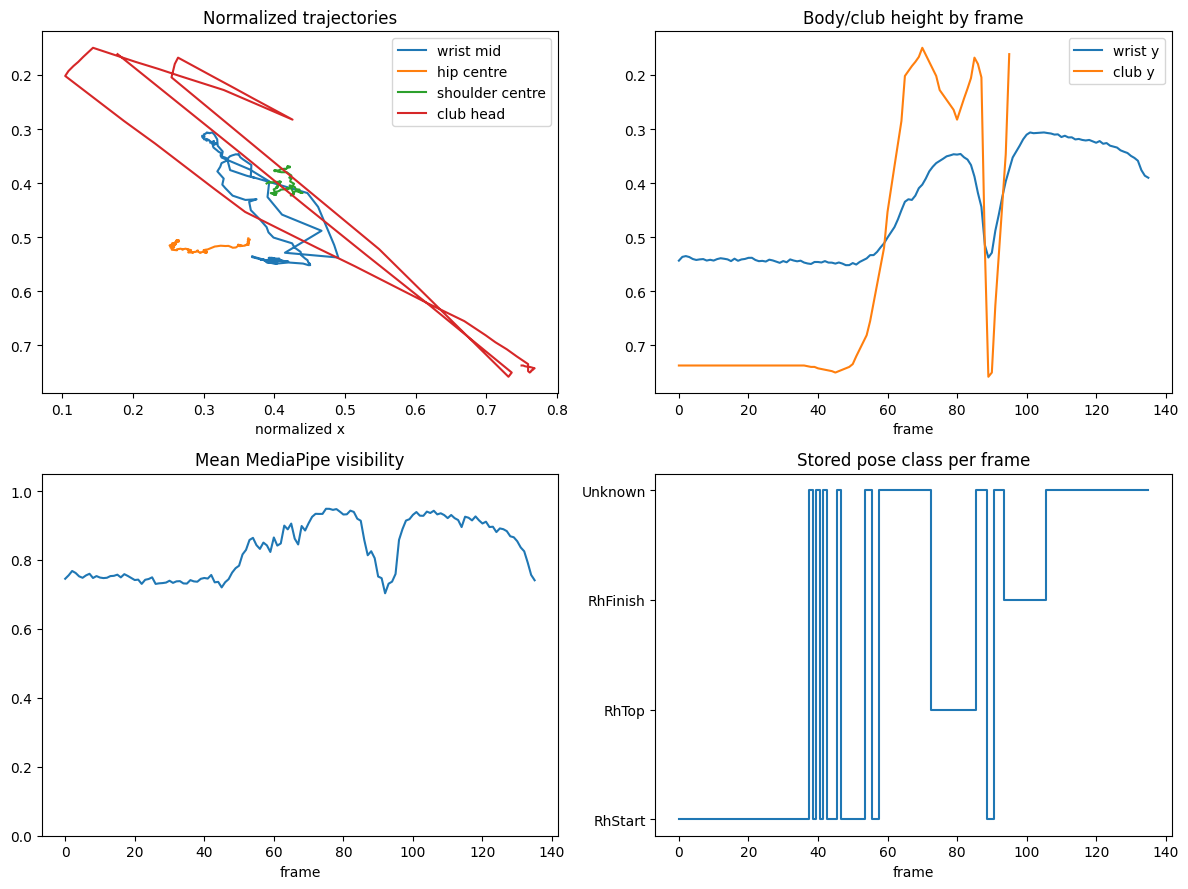

In [6]:
pose_df["wrist_x"] = pose_df[["left_wrist_x","right_wrist_x"]].mean(axis=1)
pose_df["wrist_y"] = pose_df[["left_wrist_y","right_wrist_y"]].mean(axis=1)
pose_df["hip_x"] = pose_df[["left_hip_x","right_hip_x"]].mean(axis=1)
pose_df["hip_y"] = pose_df[["left_hip_y","right_hip_y"]].mean(axis=1)
pose_df["shoulder_x"] = pose_df[["left_shoulder_x","right_shoulder_x"]].mean(axis=1)
pose_df["shoulder_y"] = pose_df[["left_shoulder_y","right_shoulder_y"]].mean(axis=1)
pose_df["mean_visibility"] = pose_df[[c for c in cols if c.endswith("_v")]].mean(axis=1)

fig, axes = plt.subplots(2,2,figsize=(12,9))
for x,y,label in [("wrist_x","wrist_y","wrist mid"),("hip_x","hip_y","hip centre"),("shoulder_x","shoulder_y","shoulder centre"),("club_head_x","club_head_y","club head")]:
    axes[0,0].plot(pose_df[x],pose_df[y],label=label)
axes[0,0].invert_yaxis(); axes[0,0].legend(); axes[0,0].set_title("Normalized trajectories")
axes[0,1].plot(pose_df.frame,pose_df.wrist_y,label="wrist y"); axes[0,1].plot(pose_df.frame,pose_df.club_head_y,label="club y")
axes[0,1].invert_yaxis(); axes[0,1].legend(); axes[0,1].set_title("Body/club height by frame")
axes[1,0].plot(pose_df.frame,pose_df.mean_visibility); axes[1,0].set_ylim(0,1.05); axes[1,0].set_title("Mean MediaPipe visibility")
phase_codes=pd.Categorical(pose_df.phase,categories=["RhStart","RhTop","RhFinish","Unknown"]).codes
axes[1,1].step(pose_df.frame,phase_codes,where="mid"); axes[1,1].set_yticks(range(4),["RhStart","RhTop","RhFinish","Unknown"]); axes[1,1].set_title("Stored pose class per frame")
for ax in axes.flat: ax.set_xlabel("frame" if ax is not axes[0,0] else "normalized x")
fig.tight_layout(); fig.savefig(OUT/"00001_trajectories.png",dpi=140)
plt.show()

## Club tracking: what really happens

The supplied club points are 24 manual `Label` positions plus 72 `LinearFit` positions and 40 `Invalid` positions. Interpolation is straight in image space and only fills gaps bracketed by labels. It has no motion model, confidence, optical flow, appearance model, automatic initialization, or correction audit beyond the `algo` string.

The package draws a line from MediaPipe's right thumb to the club-head point. That drawn segment is not a detected shaft. The current schema has no ball coordinate. Earlier documentation mentions OpenCV trackers and ball/heel/toe/grip concepts, but those are not implemented in the published 2.0 data model reviewed here.

In [7]:
params = club_head_params.ClubHeadParams()
params.club_head_points_dict = {0:(0.20,0.80), 10:(0.40,0.30)}
demo = club_head_detector.ClubHeadDetector(params).run(gs)
display(pd.DataFrame({"frame":range(11),"point":demo.norm_points[:11],"source":demo.algos[:11]}))

,frame,point,source
0,0,"(0.2, 0.8)",Label
1,1,"[0.2152777777777778, 0.75390625]",LinearFit
2,2,"[0.2337962962962963, 0.7083333333333334]",LinearFit
3,3,"[0.2523148148148148, 0.6627604166666666]",LinearFit
4,4,"[0.2708333333333333, 0.6171875]",LinearFit
5,5,"[0.28935185185185186, 0.5716145833333334]",LinearFit
6,6,"[0.3055555555555556, 0.5260416666666666]",LinearFit
7,7,"[0.32407407407407407, 0.48046875]",LinearFit
8,8,"[0.3425925925925926, 0.4348958333333333]",LinearFit
9,9,"[0.3611111111111111, 0.3893229166666667]",LinearFit


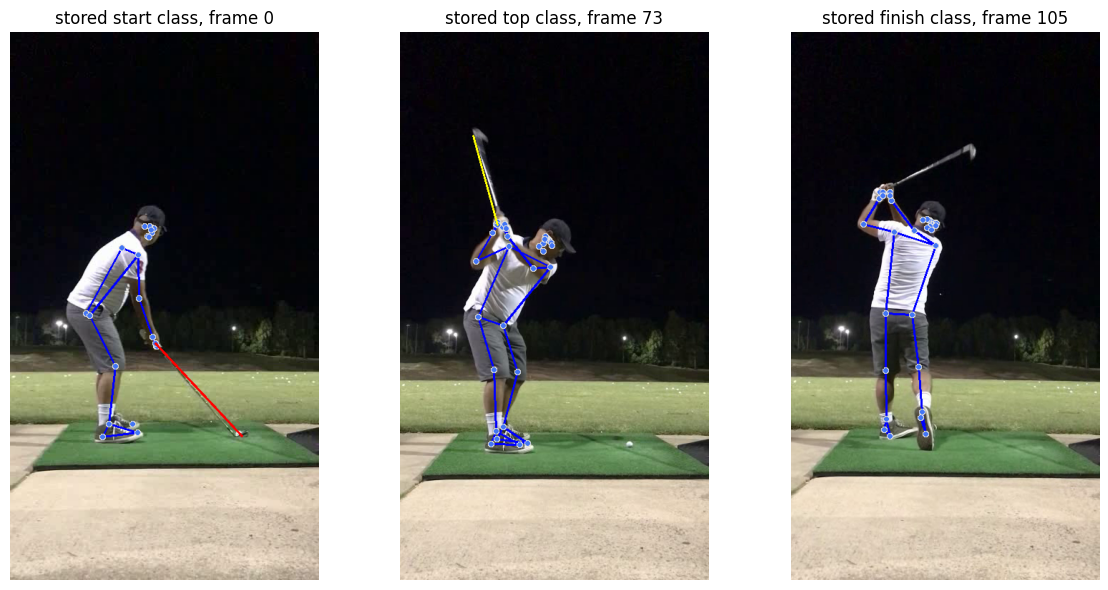

In [8]:
cap = cv2.VideoCapture(str(SAMPLES/"00001.mov"))
key_indices = {
    "start": gs.pose_result.get_first_start_pose_frame_idx(),
    "top": next(i for i,p in enumerate(gs.pose_result.poses) if p.name=="RhTop"),
    "finish": gs.pose_result.get_last_finish_pose_frame_idx(),
}
fig,axes=plt.subplots(1,3,figsize=(12,6))
for ax,(name,idx) in zip(axes,key_indices.items()):
    cap.set(cv2.CAP_PROP_POS_FRAMES,idx); ok,frame=cap.read()
    if ok:
        gs.draw_frame(idx,frame)
        ax.imshow(cv2.cvtColor(frame,cv2.COLOR_BGR2RGB))
    ax.set_title(f"stored {name} class, frame {idx}"); ax.axis("off")
cap.release(); fig.tight_layout(); fig.savefig(OUT/"00001_labelled_key_frames.png",dpi=140)
plt.show()

## Export and compatibility findings

`GolfSwing.to_json` in 2.0 emits a raw `mp_result` list and no top-level `version`. `golftrainer` 1.0.2 expects `version` plus `mp_result={landmarks,norm_points}`. Therefore the currently published producer and consumer do not interoperate directly. Only supplied `00001.json` has the consumer's required schema; samples 00002–00004 omit `version`.

Strengths: best continuous raw-data retention here; 33 landmarks with `z` and visibility; pickle/JSON concepts; manual provenance for club points; useful geometry/path utilities.

Weaknesses: broken wheel/CLIs and unreproducible pin; all frames held in RAM; model recreated per frame; unsafe/version-fragile pickle; tiny, opaque pose model with no temporal logic; manual phases/club labelling; straight-line club interpolation; no ball/shaft; producer-consumer schema drift.

In [9]:
print("EXECUTED_OK: golftracker notebook reached the final cell")

EXECUTED_OK: golftracker notebook reached the final cell
